# 01 – Eksploracyjna analiza danych (EDA)

**Cel:** zanim zbudujemy model, chcemy rozumieć dane. Każda sekcja odpowiada na jedno pytanie,
które wpływa na decyzje modelowe, i kończy się ramką **„Co z tego wynika dla modelu”**.

**Pytania:**
1. Czy dane są kompletne i czyste?
2. Jak wygląda zapotrzebowanie w czasie (doba, tydzień, rok)?
3. Jak zapotrzebowanie zależy od temperatury?
4. Czym różnią się dwie zimy w danych i co to oznacza dla walidacji?
5. Czy zapotrzebowanie rośnie z roku na rok?
6. Jak bardzo spada zużycie w święta, dni mostowe i okres świąteczny?
7. Czy widać wpływ fotowoltaiki?
8. Które przeszłe wartości najlepiej przewidują przyszłość (autokorelacja)?
9. Gdzie myli się prognoza PSE, czyli gdzie mamy szansę ją pobić?

**Dane:** tabela cech `data/processed/features.parquet` (1 wiersz = 1 godzina UTC, z pogodą i kalendarzem),
zbudowana poleceniem `python -m kse_forecast build-features`, oraz surowe dane PSE do kontroli jakości.

**Ważne, czyli brak podglądania holdoutu:** analizujemy wyłącznie **zbiór deweloperski**, czyli dane sprzed
`HOLDOUT_START` (1.09.2026). Ostatnie miesiące są odłożone na jedną, końcową ocenę modelu. Gdybyśmy je tu
oglądali, nasze decyzje (wybór cech, modelu) byłyby „dopasowane” do danych testowych, a końcowy wynik
wyszedłby zbyt optymistyczny. Wyjątkiem jest sekcja 1 (jakość danych): sprawdzamy w niej kompletność
całego pliku, ale nie zależności w danych.

Komentarze opisują dane deweloperskie od 22.06.2024 do 31.08.2026.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from kse_forecast.config import FEATURES_PATH, HOLDOUT_START, LOAD_RAW_PATH, LOCAL_TZ
from kse_forecast.validation import split_holdout

# Spójny wygląd wykresów: cienkie linie, delikatna siatka, stałe kolory serii.
plt.rcParams.update(
    {
        "figure.figsize": (12, 4),
        "figure.dpi": 100,
        "axes.grid": True,
        "grid.alpha": 0.3,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "lines.linewidth": 1.5,
        "font.size": 10,
    }
)
BLUE, ORANGE, AQUA, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#8c8c8c"

raw = pd.read_parquet(LOAD_RAW_PATH)
df, _ = split_holdout(pd.read_parquet(FEATURES_PATH))  # holdoutu nie oglądamy
print("Holdout zaczyna się:", HOLDOUT_START.date())

# Doba liczona po polsku (czas lokalny), bo tak żyją odbiorcy energii.
local = df.index.tz_convert(LOCAL_TZ)
df["date"] = pd.to_datetime(local.date)
df["season"] = np.select(
    [df["month"].isin([12, 1, 2]), df["month"].isin([6, 7, 8])], ["zima", "lato"], "wiosna/jesień"
)
df["day_type"] = np.select([df["is_holiday"] == 1, df["is_weekend"] == 1], ["święto", "weekend"], "roboczy")

daily = df.groupby("date").agg(
    load=("load_actual", "mean"),
    fcst=("load_fcst", "mean"),
    temp=("temperature_2m", "mean"),
    is_weekend=("is_weekend", "max"),
    is_holiday=("is_holiday", "max"),
    dayofweek=("dayofweek", "first"),
)
workdays = daily[(daily["is_weekend"] == 0) & (daily["is_holiday"] == 0)]
print(f"Godziny: {len(df)}  ({df.index.min()} -> {df.index.max()})")
print(f"Dni: {len(daily)}, w tym roboczych: {len(workdays)}")

Holdout zaczyna się: 2026-09-01
Godziny: 19201  (2024-06-22 21:00:00+00:00 -> 2026-08-31 21:00:00+00:00)
Dni: 801, w tym roboczych: 551


## 1. Jakość danych

Sprawdzamy trzy rzeczy: braki wartości, duplikaty i liczbę kwadransów na dobę.
Normalna doba ma 96 kwadransów, a w dni zmiany czasu 92 (wiosną, doba ma 23 h) lub 100 (jesienią, 25 h).

In [2]:
print("Braki w load_actual / load_fcst:", raw[["load_actual", "load_fcst"]].isna().sum().tolist())
print("Zduplikowane znaczniki czasu:", raw["dtime_utc"].duplicated().sum())

per_day = raw.groupby("business_date").size()
print("\nLiczba kwadransów na dobę -> liczba dni:")
print(per_day.value_counts().to_string())
print("\nDni z liczbą kwadransów inną niż 96:")
print(per_day[per_day != 96].to_string())

full_range = pd.date_range(df.index.min(), df.index.max(), freq="h")
print("\nBrakujące godziny w tabeli cech:", len(full_range) - len(df))

Braki w load_actual / load_fcst: [0, 0]
Zduplikowane znaczniki czasu: 0

Liczba kwadransów na dobę -> liczba dni:
96     887
100      3
92       2

Dni z liczbą kwadransów inną niż 96:
business_date
2024-10-27    100
2025-03-30     92
2025-10-26    100
2026-03-29     92
2026-10-25    100

Brakujące godziny w tabeli cech: 0


**Wniosek:** dane są kompletne. Nie ma braków ani duplikatów, a doby z 92 i 100 kwadransami
to dokładnie dni zmiany czasu (marzec i październik). Tabela godzinowa nie ma żadnej dziury.

> **Co z tego wynika dla modelu:** nie trzeba uzupełniać braków (imputacji). Zmiana czasu
> jest obsłużona, bo pracujemy w UTC, a kalendarz liczymy w czasie polskim.

## 2. Zapotrzebowanie w czasie

Średnia dobowa zapotrzebowania i temperatura dla całego okresu. Są na dwóch osobnych
wykresach ze wspólną osią czasu, bo mają różne jednostki (MW i °C).

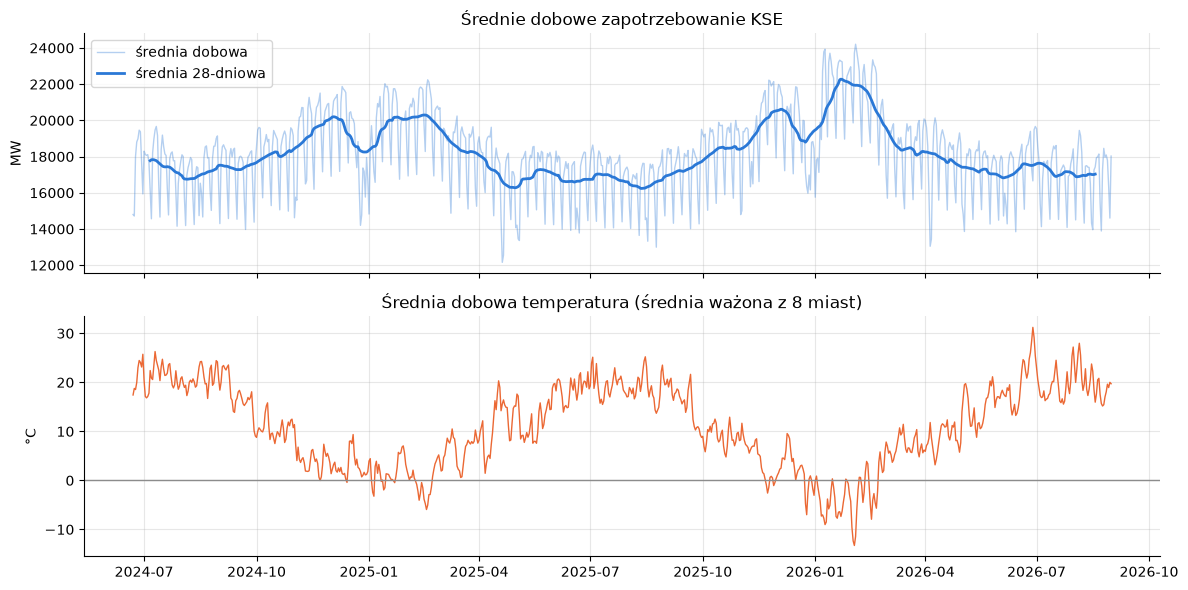

count    19201.0
mean     18167.0
std       3101.0
min      10596.0
25%      15649.0
50%      18301.0
75%      20243.0
max      27604.0

Maksimum: 2026-02-03 09:00:00+01:00 27604 MW
Minimum:  2025-04-21 05:00:00+02:00 10596 MW


In [3]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
ax1.plot(daily.index, daily["load"], color=BLUE, alpha=0.35, linewidth=1, label="średnia dobowa")
ax1.plot(
    daily.index,
    daily["load"].rolling(28, center=True).mean(),
    color=BLUE,
    linewidth=2,
    label="średnia 28-dniowa",
)
ax1.set_ylabel("MW")
ax1.set_title("Średnie dobowe zapotrzebowanie KSE")
ax1.legend(loc="upper left")
ax2.plot(daily.index, daily["temp"], color=ORANGE, linewidth=1)
ax2.axhline(0, color=GREY, linewidth=1)
ax2.set_ylabel("°C")
ax2.set_title("Średnia dobowa temperatura (średnia ważona z 8 miast)")
plt.tight_layout()
plt.show()

print(df["load_actual"].describe().round(0).to_string())
print("\nMaksimum:", df["load_actual"].idxmax().tz_convert(LOCAL_TZ), round(df["load_actual"].max()), "MW")
print("Minimum: ", df["load_actual"].idxmin().tz_convert(LOCAL_TZ), round(df["load_actual"].min()), "MW")

**Wniosek:**
- Zapotrzebowanie waha się od ok. **10,6 GW do 27,6 GW**, a średnio wynosi ok. 18,2 GW.
- Wyraźny rytm roczny: zimą wyżej, latem niżej. Zapotrzebowanie jest niemal lustrzanym odbiciem temperatury.
- **Maksimum** przypadło 3 lutego 2026 o 9:00 w czasie polskim (najmroźniejsza zima w danych),
  a **minimum** na Poniedziałek Wielkanocny 2025 o 5:00 rano, czyli w święto, w nocy i wiosną.
- Na wykresie widać ostre spadki w okolicach świąt Bożego Narodzenia i Nowego Roku.

> **Co z tego wynika dla modelu:** temperatura i kalendarz to dwa główne źródła zmienności.
> Skrajne wartości mają proste wyjaśnienie, więc nie są błędami danych i nie należy ich usuwać.

## 3. Profile: doba, tydzień, rok

### 3a. Profil dobowy według rodzaju dnia i pory roku

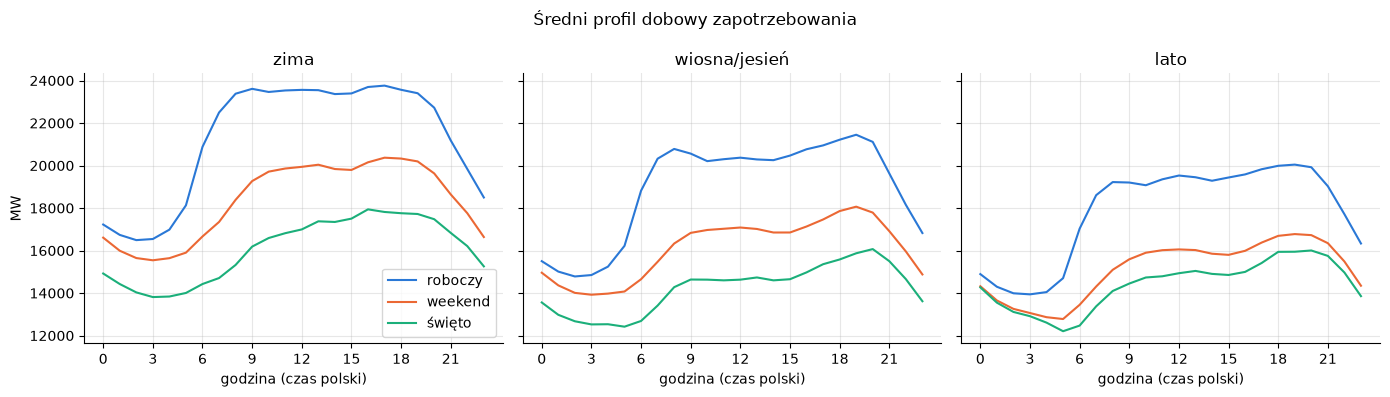

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
colors = {"roboczy": BLUE, "weekend": ORANGE, "święto": AQUA}
for ax, season in zip(axes, ["zima", "wiosna/jesień", "lato"], strict=False):
    sub = df[df["season"] == season]
    for day_type, color in colors.items():
        profile = sub[sub["day_type"] == day_type].groupby("hour")["load_actual"].mean()
        ax.plot(profile.index, profile.values, color=color, label=day_type)
    ax.set_title(season)
    ax.set_xlabel("godzina (czas polski)")
    ax.set_xticks(range(0, 24, 3))
axes[0].set_ylabel("MW")
axes[0].legend()
plt.suptitle("Średni profil dobowy zapotrzebowania")
plt.tight_layout()
plt.show()

**Wniosek:**
- W dzień roboczy zapotrzebowanie rośnie gwałtownie między 5:00 a 8:00 i utrzymuje się wysoko do wieczora.
  Zimą to płaskie „plateau” od ok. 9:00 do 18:00. Wiosną, jesienią i latem widać za to wyraźny
  **szczyt wieczorny ok. 19:00–20:00** (powrót do domu, oświetlenie, a latem także zachód słońca,
  po którym fotowoltaika przestaje produkować).
- W weekend poranny wzrost jest późniejszy i dużo mniejszy.
- Profil święta jest **niższy nawet niż weekendowy**, bo w święta stoi także część przemysłu,
  który pracuje w soboty. Latem w nocy różnica między świętem a weekendem prawie znika.
- Zimą cały profil jest przesunięty w górę o ok. 2–3 GW względem lata.

> **Co z tego wynika dla modelu:** kształt doby zależy od rodzaju dnia i pory roku jednocześnie
> (interakcja). Model musi mieć cechy `hour`, `dayofweek`, `is_holiday` i `month` naraz.
> Prosta regresja liniowa nie wyłapie takich interakcji, chyba że dodamy je ręcznie.

### 3b. Profil tygodniowy

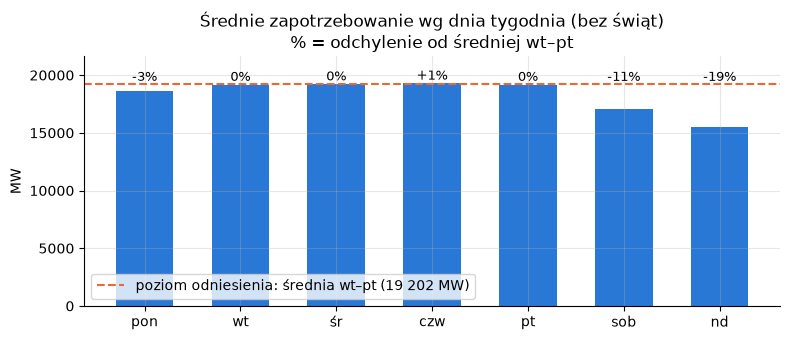

In [5]:
names = ["pon", "wt", "śr", "czw", "pt", "sob", "nd"]
by_dow = df[df["is_holiday"] == 0].groupby("dayofweek")["load_actual"].mean()
mid_week = by_dow.loc[1:4].mean()

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.bar(names, by_dow.values, color=BLUE, width=0.6)
# Poziom odniesienia (0%) to średnia z wtorku-piątku, czyli "typowy dzień roboczy".
ax.axhline(
    mid_week,
    color=ORANGE,
    linestyle="--",
    linewidth=1.5,
    label=f"poziom odniesienia: średnia wt–pt ({mid_week:,.0f} MW)".replace(",", " "),
)
ax.legend(loc="lower left")
for i, v in enumerate(by_dow.values):
    pct = round((v / mid_week - 1) * 100)
    ax.text(i, max(v, mid_week) + 300, f"{pct:+d}%" if pct else "0%", ha="center", fontsize=9)
ax.set_ylim(0, by_dow.max() * 1.12)
ax.set_ylabel("MW")
ax.set_title("Średnie zapotrzebowanie wg dnia tygodnia (bez świąt)\n% = odchylenie od średniej wt–pt")
plt.tight_layout()
plt.show()

**Jak czytać wykres:** słupek to średnie zapotrzebowanie ze wszystkich godzin danego dnia tygodnia (bez świąt).
Punktem odniesienia (0%, linia przerywana) jest średnia z wtorku–piątku, czyli „typowy dzień roboczy”.
Procent nad słupkiem mówi, o ile dany dzień różni się od tego poziomu. Przykładowo −19% dla niedzieli znaczy,
że w niedzielę zużywamy średnio 81% tego, co w typowy dzień roboczy. Poniedziałek nie wchodzi do odniesienia,
bo jest trochę nietypowy (patrz niżej).

**Wniosek:** wtorek–piątek są do siebie bardzo podobne. **Poniedziałek jest ok. 3% niżej**,
bo jego pierwsze godziny to jeszcze „niedzielna noc”, a przemysł się rozkręca.
**Sobota to ok. −11%, a niedziela ok. −19%.**

> **Co z tego wynika dla modelu:** sam `is_weekend` nie wystarczy, potrzebny jest pełny `dayofweek`.
> Lag 48 h jest zdradliwy w poniedziałek (wskazuje na sobotę) i we wtorek (wskazuje na niedzielę).
> Wrócimy do tego w sekcji 9.

### 3c. Profil roczny, czyli średnie miesięczne w kolejnych latach

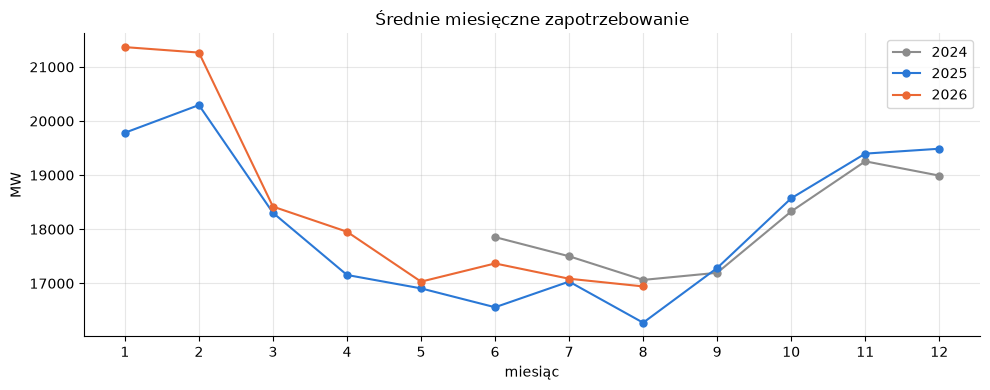

Uwaga: czerwiec 2024 to tylko ostatni tydzień miesiąca (tabela cech zaczyna się 22.06.2024).


In [6]:
monthly = df.groupby([df["date"].dt.year, df["date"].dt.month])["load_actual"].mean().unstack(0)
fig, ax = plt.subplots(figsize=(10, 4))
for year, color in zip(monthly.columns, [GREY, BLUE, ORANGE], strict=False):
    ax.plot(monthly.index, monthly[year], marker="o", markersize=5, color=color, label=str(year))
ax.set_xticks(range(1, 13))
ax.set_xlabel("miesiąc")
ax.set_ylabel("MW")
ax.set_title("Średnie miesięczne zapotrzebowanie")
ax.legend()
plt.tight_layout()
plt.show()
print("Uwaga: czerwiec 2024 to tylko ostatni tydzień miesiąca (tabela cech zaczyna się 22.06.2024).")

**Wniosek:** najwyższe zapotrzebowanie przypada na styczeń i luty, najniższe na maj–sierpień.
Rok 2026 leży w większości miesięcy **powyżej** roku 2025, ale nie wiadomo jeszcze, czy to trend,
czy pogoda. Styczeń 2026 był wyjątkowo mroźny (sekcja 5), a czy jest trend, sprawdzimy w sekcji 6.

## 4. Zapotrzebowanie a temperatura

Bierzemy tylko **dni robocze**, żeby wpływ kalendarza nie zamazywał wpływu pogody.
Jeden punkt to jedna doba: średnia temperatura i średnie zapotrzebowanie.

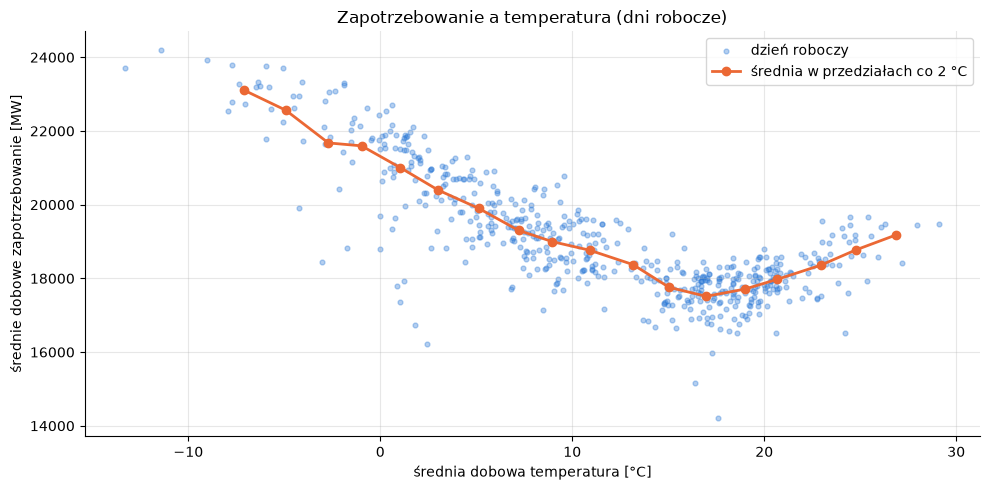

Korelacja (dni robocze): -0.79


In [7]:
bins = np.arange(-14, 31, 2)
binned = workdays.groupby(pd.cut(workdays["temp"], bins), observed=True).agg(
    temp=("temp", "mean"), load=("load", "mean"), n=("load", "size")
)
binned = binned[binned["n"] >= 3]  # przedziały z 1-2 dniami są zbyt losowe

fig, ax = plt.subplots(figsize=(10, 5))
ax.scatter(workdays["temp"], workdays["load"], s=12, color=BLUE, alpha=0.35, label="dzień roboczy")
ax.plot(
    binned["temp"],
    binned["load"],
    color=ORANGE,
    linewidth=2,
    marker="o",
    markersize=6,
    label="średnia w przedziałach co 2 °C",
)
ax.set_xlabel("średnia dobowa temperatura [°C]")
ax.set_ylabel("średnie dobowe zapotrzebowanie [MW]")
ax.set_title("Zapotrzebowanie a temperatura (dni robocze)")
ax.legend()
plt.tight_layout()
plt.show()

print("Korelacja (dni robocze):", round(workdays[["load", "temp"]].corr().iloc[0, 1], 2))

Zależność wygląda jak litera **U**, ale bardzo niesymetryczna. Sprawdźmy liczbowo, gdzie są „punkty
załamania”. Dopasowujemy prosty model z dwoma progami: poniżej `T_heat` zapotrzebowanie rośnie z mrozem
(ogrzewanie), a powyżej `T_cool` rośnie z upałem (klimatyzacja). Szukamy progów z najmniejszym błędem.

In [8]:
def fit_degrees(data, t_heat, t_cool):
    X = np.column_stack(
        [np.ones(len(data)), np.clip(t_heat - data["temp"], 0, None), np.clip(data["temp"] - t_cool, 0, None)]
    )
    coef, *_ = np.linalg.lstsq(X, data["load"], rcond=None)
    rmse = np.sqrt(np.mean((data["load"] - X @ coef) ** 2))
    return coef, rmse


results = [(t_h, t_c, *fit_degrees(workdays, t_h, t_c)) for t_h in range(10, 21) for t_c in range(t_h, 27)]
best = min(results, key=lambda r: r[3])
current = next(r for r in results if r[:2] == (15, 22))

for label, (t_h, t_c, coef, rmse) in [("Najlepsze progi", best), ("Obecne progi w features.py", current)]:
    print(f"{label}: grzanie poniżej {t_h} °C, chłodzenie powyżej {t_c} °C")
    print(
        f"   +{coef[1]:.0f} MW na każdy stopień zimna, +{coef[2]:.0f} MW na każdy stopień upału,"
        f" RMSE {rmse:.0f} MW"
    )

Najlepsze progi: grzanie poniżej 15 °C, chłodzenie powyżej 19 °C


   +240 MW na każdy stopień zimna, +196 MW na każdy stopień upału, RMSE 789 MW
Obecne progi w features.py: grzanie poniżej 15 °C, chłodzenie powyżej 22 °C
   +232 MW na każdy stopień zimna, +343 MW na każdy stopień upału, RMSE 799 MW


**Wniosek:**
- Korelacja dobowa wynosi ok. **−0,79**: im zimniej, tym większe zapotrzebowanie. To najsilniejsza zależność w danych.
- **Ogrzewanie:** każdy stopień poniżej ok. 15 °C to ok. **+240 MW**. Zależność jest prawie **liniowa aż do −10 °C**,
  nie wypłaszcza się przy mrozie.
- **Chłodzenie:** powyżej ok. 19 °C zapotrzebowanie rośnie o ok. 200 MW na stopień, ale gorących dni jest mało,
  więc ta część jest mniej pewna.
- Dolne „odstające” punkty na wykresie (14–17 GW przy umiarkowanej temperaturze) to dni robocze
  w okresie świątecznym i dni mostowe. Wrócimy do nich w sekcji 7.
- Obecne progi w `features.py` (15 °C i 22 °C) dają prawie ten sam błąd (RMSE ok. 800 MW wobec 790 MW), więc nie
  trzeba ich pilnie zmieniać. Próg grzania (15 °C) zgadza się z danymi, a próg chłodzenia dane wskazują niżej, ok. 19 °C.
  Drzewa (LightGBM) i tak same znajdują progi w surowej temperaturze, więc ma to znaczenie głównie dla modeli liniowych.

> **Co z tego wynika dla modelu:** skoro zależność od zimna jest liniowa, to model **liniowy**
> (regresja albo LightGBM z `linear_tree=True`) może sensownie przewidywać temperatury spoza danych
> treningowych. Zwykłe drzewa tego nie umieją, bo przy mrozie spoza treningu podają wartość z najzimniejszego
> dnia, jaki widziały.

## 5. Dwie zimy w danych i co to oznacza dla walidacji

W danych deweloperskich są dokładnie dwie zimy. Porównujemy rozkład temperatur godzinowych
w sezonie grzewczym (listopad–marzec) 2024/25 i 2025/26.

Dlaczego to ważne: w walidacji krzyżowej (notebook 02) model przewidujący np. styczeń 2026 uczy się
tylko na danych sprzed stycznia 2026, czyli z jedną pełną zimą (2024/25).

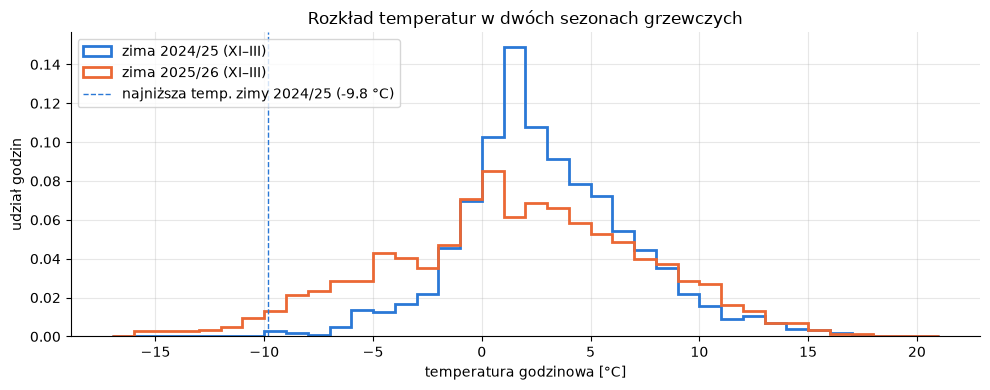

                           zima 2024/25  zima 2025/26
średnia temp. [°C]                  3.0           1.5
min. temp. godzinowa [°C]          -9.8         -15.6
1. percentyl [°C]                  -6.0         -12.8
godziny poniżej −5 °C              87.0         513.0
najzimniejsza doba [°C]            -5.9         -13.3

Godziny zimy 2025/26 zimniejsze niż cokolwiek w zimie 2024/25: 104

Miesiące zimowe (średnie):
            temp     load
date                     
2024-12-01   2.8  18991.2
2025-01-01   1.9  19783.5
2025-02-01  -0.3  20295.1
2025-12-01   2.2  19487.9
2026-01-01  -4.3  21366.2
2026-02-01  -1.6  21265.2


In [9]:
def heating_season(start_year: int) -> pd.Series:
    start = pd.Timestamp(f"{start_year}-11-01", tz=LOCAL_TZ)
    end = pd.Timestamp(f"{start_year + 1}-04-01", tz=LOCAL_TZ)
    return df.loc[(df.index >= start) & (df.index < end), "temperature_2m"]


w1, w2 = heating_season(2024), heating_season(2025)

fig, ax = plt.subplots(figsize=(10, 4))
bins_t = np.arange(-17, 22, 1)
ax.hist(
    w1, bins=bins_t, density=True, histtype="step", linewidth=2, color=BLUE, label="zima 2024/25 (XI–III)"
)
ax.hist(
    w2, bins=bins_t, density=True, histtype="step", linewidth=2, color=ORANGE, label="zima 2025/26 (XI–III)"
)
ax.axvline(
    w1.min(),
    color=BLUE,
    linestyle="--",
    linewidth=1,
    label=f"najniższa temp. zimy 2024/25 ({w1.min():.1f} °C)",
)
ax.set_xlabel("temperatura godzinowa [°C]")
ax.set_ylabel("udział godzin")
ax.set_title("Rozkład temperatur w dwóch sezonach grzewczych")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()


def daily_min(s: pd.Series) -> float:
    return s.groupby(s.index.tz_convert(LOCAL_TZ).date).mean().min()


summary = pd.DataFrame(
    {
        "zima 2024/25": [w1.mean(), w1.min(), w1.quantile(0.01), (w1 < -5).sum(), daily_min(w1)],
        "zima 2025/26": [w2.mean(), w2.min(), w2.quantile(0.01), (w2 < -5).sum(), daily_min(w2)],
    },
    index=[
        "średnia temp. [°C]",
        "min. temp. godzinowa [°C]",
        "1. percentyl [°C]",
        "godziny poniżej −5 °C",
        "najzimniejsza doba [°C]",
    ],
)
print(summary.round(1).to_string())
print("\nGodziny zimy 2025/26 zimniejsze niż cokolwiek w zimie 2024/25:", (w2 < w1.min()).sum())

winter = daily[daily.index.month.isin([12, 1, 2])]
print("\nMiesiące zimowe (średnie):")
print(winter.resample("MS")[["temp", "load"]].mean().dropna().round(1).to_string())

**Wniosek:**
- Zima 2024/25 była łagodna: najniższa temperatura ok. −10 °C, a najzimniejsza doba ok. −6 °C.
- Zima 2025/26 była **wyraźnie mroźniejsza**: do ok. −16 °C, najzimniejsza doba ok. −13 °C,
  a godzin poniżej −5 °C było ok. **6 razy więcej**.
- Ponad 100 godzin zimy 2025/26 było zimniejszych niż cokolwiek z poprzedniej zimy.
- Styczeń 2026: średnio −4,3 °C i ok. 21,4 GW, a rok wcześniej +1,9 °C i ok. 19,8 GW.

> **Co z tego wynika dla modelu:** w walidacji krzyżowej foldy grudzień 2025 – luty 2026 będą trudne.
> To nie musi oznaczać „złego modelu”, tylko klasyczny problem **ekstrapolacji**: model ma przewidzieć
> warunki, których nie widział. Możliwe rozwiązania: (1) model, który ekstrapoluje liniowo (sekcja 4),
> (2) częste douczanie, (3) więcej historii. Punkt 3 odpada, bo PSE udostępnia dane dopiero od 2024-06-14.
> Wynik CV warto więc raportować także **osobno dla zimy**, a nie tylko jako jedną średnią.

## 6. Czy zapotrzebowanie rośnie z roku na rok?

Porównanie „rok do roku” jest mylące, bo każdy rok ma inną pogodę. Dlatego najpierw usuwamy wpływ temperatury,
a potem patrzymy, czy **reszta** (to, czego temperatura nie wyjaśnia) rośnie w czasie.

**Model temperatury** to regresja liniowa „stopniodni” z sekcji 4 (funkcja `fit_degrees`, najlepsze progi `best`),
dopasowana do średnich dobowych w dni robocze:

```
zapotrzebowanie ≈ a + b × max(15 °C − temperatura, 0) + c × max(temperatura − 19 °C, 0)
```

gdzie `a` ≈ 17,6 GW (dzień roboczy bez grzania i chłodzenia), `b` ≈ 240 MW/°C (ogrzewanie), a `c` ≈ 200 MW/°C (klimatyzacja).

**Reszta** = rzeczywiste zapotrzebowanie − to, co przewiduje ten model. Przykład: przy −5 °C model daje
17,6 + 0,24 × 20 ≈ 22,4 GW. Jeśli naprawdę było 22,7 GW, reszta wynosi +0,3 GW.
Gdyby zapotrzebowanie rosło z roku na rok (np. przez pompy ciepła), reszty miałyby trend w górę.

Celowo używamy prostego modelu, który zna **tylko temperaturę**. LightGBM korzysta też z lagów, które niosą
informację o poziomie zapotrzebowania, więc „wchłonąłby” trend, którego szukamy.

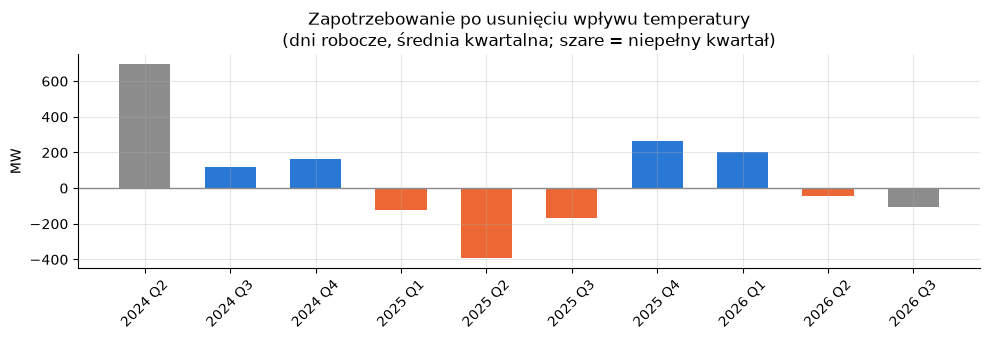

            reszta [MW]  dni
date                        
2024-04-01        696.0    5
2024-07-01        119.0   65
2024-10-01        163.0   62
2025-01-01       -121.0   62
2025-04-01       -394.0   62
2025-07-01       -170.0   65
2025-10-01        264.0   62
2026-01-01        204.0   62
2026-04-01        -45.0   62
2026-07-01       -104.0   44


In [10]:
t_h, t_c, coef, _ = best
X = np.column_stack(
    [
        np.ones(len(workdays)),
        np.clip(t_h - workdays["temp"], 0, None),
        np.clip(workdays["temp"] - t_c, 0, None),
    ]
)
residual = (workdays["load"] - X @ coef).resample("QS").agg(["mean", "size"])

fig, ax = plt.subplots(figsize=(10, 3.5))
labels = [f"{d.year} Q{d.quarter}" for d in residual.index]
# Kwartały z małą liczbą dni (początek i koniec danych) wyszarzamy, bo są mało wiarygodne.
bar_colors = [
    GREY if n < 50 else (BLUE if v >= 0 else ORANGE)
    for v, n in zip(residual["mean"], residual["size"], strict=False)
]
ax.bar(labels, residual["mean"], color=bar_colors, width=0.6)
ax.axhline(0, color=GREY, linewidth=1)
ax.set_ylabel("MW")
ax.set_title(
    "Zapotrzebowanie po usunięciu wpływu temperatury\n"
    "(dni robocze, średnia kwartalna; szare = niepełny kwartał)"
)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()
print(residual.round(0).rename(columns={"mean": "reszta [MW]", "size": "dni"}).to_string())

**Wniosek:** **nie widać wyraźnego trendu.** Reszty skaczą o ±400 MW między kwartałami bez stałego kierunku.
Szare słupki (2024 Q2 i 2026 Q3) to niepełne kwartały, zbudowane z kilku tygodni, więc nie można na nich
polegać. Przy 2,5 roku danych nie da się uczciwie stwierdzić, czy np. pompy ciepła albo samochody elektryczne
podnoszą zapotrzebowanie.

> **Co z tego wynika dla modelu:** nie dodajemy cechy „trend” (np. numeru roku), bo na tak krótkiej historii
> model mógłby ją źle ekstrapolować. Powolne zmiany poziomu obsłuży cecha `load_mean_7d` i regularne douczanie.

## 7. Święta, dni mostowe i okres świąteczny

Każdy wybrany dzień porównujemy z **medianą tego samego dnia tygodnia** z ±3 tygodni (bez świąt).
Wynik to procentowe odchylenie, np. −20% oznacza, że zużycie było o jedną piątą niższe niż w typowy dzień.

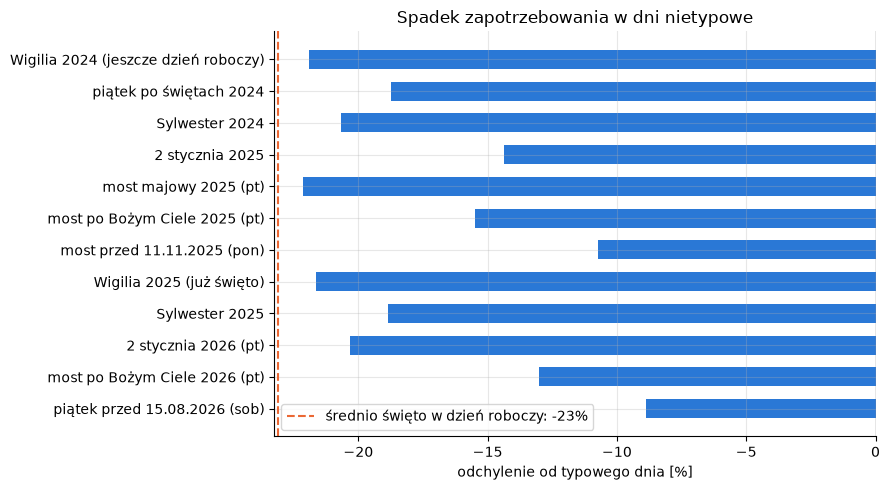

Święta wypadające w dni robocze (20 dni): średnio -23.1%
                                            opis  odchylenie
2024-12-24  Wigilia 2024 (jeszcze dzień roboczy)       -21.9
2024-12-27               piątek po świętach 2024       -18.7
2024-12-31                        Sylwester 2024       -20.7
2025-01-02                       2 stycznia 2025       -14.4
2025-05-02                 most majowy 2025 (pt)       -22.1
2025-06-20         most po Bożym Ciele 2025 (pt)       -15.5
2025-11-10           most przed 11.11.2025 (pon)       -10.7
2025-12-24             Wigilia 2025 (już święto)       -21.6
2025-12-31                        Sylwester 2025       -18.9
2026-01-02                  2 stycznia 2026 (pt)       -20.3
2026-06-05         most po Bożym Ciele 2026 (pt)       -13.0
2026-08-14         piątek przed 15.08.2026 (sob)        -8.9


In [11]:
def deviation(day):
    day = pd.Timestamp(day)
    ref = daily[
        (daily["dayofweek"] == daily.loc[day, "dayofweek"])
        & (daily["is_holiday"] == 0)
        & (np.abs((daily.index - day).days) <= 21)
        & (daily.index != day)
    ]
    return daily.loc[day, "load"] / ref["load"].median() - 1


special = {
    "2024-12-24": "Wigilia 2024 (jeszcze dzień roboczy)",
    "2024-12-27": "piątek po świętach 2024",
    "2024-12-31": "Sylwester 2024",
    "2025-01-02": "2 stycznia 2025",
    "2025-05-02": "most majowy 2025 (pt)",
    "2025-06-20": "most po Bożym Ciele 2025 (pt)",
    "2025-11-10": "most przed 11.11.2025 (pon)",
    "2025-12-24": "Wigilia 2025 (już święto)",
    "2025-12-31": "Sylwester 2025",
    "2026-01-02": "2 stycznia 2026 (pt)",
    "2026-06-05": "most po Bożym Ciele 2026 (pt)",
    "2026-08-14": "piątek przed 15.08.2026 (sob)",
}
table = pd.DataFrame(
    {"opis": special.values(), "odchylenie": [deviation(d) for d in special]}, index=special.keys()
)

weekday_holidays = daily[(daily["is_holiday"] == 1) & (daily["dayofweek"] < 5)].index
avg_holiday = np.mean([deviation(d) for d in weekday_holidays])

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(table["opis"], table["odchylenie"] * 100, color=BLUE, height=0.6)
ax.axvline(
    avg_holiday * 100,
    color=ORANGE,
    linestyle="--",
    linewidth=1.5,
    label=f"średnio święto w dzień roboczy: {avg_holiday:.0%}",
)
ax.legend(loc="lower left")
ax.axvline(0, color=GREY, linewidth=1)
ax.invert_yaxis()
ax.set_xlabel("odchylenie od typowego dnia [%]")
ax.set_title("Spadek zapotrzebowania w dni nietypowe")
plt.tight_layout()
plt.show()

print(f"Święta wypadające w dni robocze ({len(weekday_holidays)} dni): średnio {avg_holiday:.1%}")
print(table.assign(odchylenie=(table["odchylenie"] * 100).round(1)).to_string())

**Wniosek:**
- Święto w dzień roboczy obniża zapotrzebowanie średnio o ok. **23%**.
- **Dni mostowe zachowują się prawie jak święta:** most majowy 2025 dał ok. −22%, czyli tyle co święto,
  a piątki po Bożym Ciele ok. −13 do −16%. Tymczasem nasza cecha `is_holiday` ma dla nich wartość 0.
- **Okres od Wigilii do Nowego Roku** to −14 do −22%, choć formalnie to dni robocze.
- **Wigilia 2024** (jeszcze dzień roboczy) i **Wigilia 2025** (już święto) dały praktycznie ten sam spadek, ok. −22%.
  Dla zużycia prądu liczy się to, czy ludzie pracują, a nie status prawny dnia.

> **Co z tego wynika dla modelu:** warto dodać cechy `is_bridge_day` (dzień roboczy między świętem a weekendem)
> i `is_christmas_period` (24.12–6.01). Bez nich model myli się w tych dniach o kilka GW.
> Uwaga: te dni są rzadkie (kilka w roku), więc model nauczy się ich efektu z małej liczby przykładów.

## 8. Fotowoltaika: czy słońce obniża zapotrzebowanie?

Instalacje PV na dachach domów i firm produkują prąd „za licznikiem”, więc część zużycia nie przechodzi przez sieć
i PSE widzi **niższe** zapotrzebowanie. Jeśli tak jest, w słoneczne letnie południe zapotrzebowanie powinno być
niższe niż w pochmurne, mimo że przy słońcu jest goręcej (a upał zwiększa zużycie przez klimatyzację).

Bierzemy dni robocze maj–sierpień, godziny 12:00–13:00, i dzielimy je na 4 grupy według nasłonecznienia.

In [12]:
noon = df[
    df["month"].isin([5, 6, 7, 8])
    & (df["is_weekend"] == 0)
    & (df["is_holiday"] == 0)
    & df["hour"].isin([12, 13])
]
groups = pd.qcut(
    noon["shortwave_radiation"],
    4,
    labels=["najbardziej pochmurno", "pochmurno", "słonecznie", "najbardziej słonecznie"],
)
solar = noon.groupby(groups, observed=True).agg(
    radiation=("shortwave_radiation", "mean"),
    temperature=("temperature_2m", "mean"),
    load=("load_actual", "mean"),
)
print(
    solar.round(0)
    .rename(
        columns={
            "radiation": "nasłonecznienie [W/m²]",
            "temperature": "temperatura [°C]",
            "load": "zapotrzebowanie [MW]",
        }
    )
    .to_string()
)

                        nasłonecznienie [W/m²]  temperatura [°C]  zapotrzebowanie [MW]
shortwave_radiation                                                                   
najbardziej pochmurno                    459.0              19.0               19738.0
pochmurno                                608.0              21.0               19448.0
słonecznie                               687.0              23.0               19368.0
najbardziej słonecznie                   771.0              25.0               19308.0


**Wniosek:** w najbardziej słoneczne letnie południa jest średnio o ok. **6 °C cieplej**, a mimo to zapotrzebowanie
jest o ok. **400 MW niższe** niż w najbardziej pochmurne. Według sekcji 4 sam upał powinien je *podnieść*.
To jest zgodne z hipotezą, że PV za licznikiem obniża zapotrzebowanie widziane przez PSE.
Efekt jest prawdopodobnie większy, niż pokazuje ta tabela, bo upał działa w przeciwną stronę.

> **Co z tego wynika dla modelu:** `shortwave_radiation` i `cloud_cover` są ważne zwłaszcza w godzinach 10–15.
> W produkcji będziemy mieli tylko **prognozę** zachmurzenia, która jest jedną z najtrudniejszych do przewidzenia
> zmiennych pogodowych. To będzie źródło błędu w środku dnia (patrz sekcja 9).

## 9. Autokorelacja: które przeszłe wartości pomagają?

Autokorelacja mówi, jak bardzo zapotrzebowanie teraz jest podobne do zapotrzebowania *k* godzin wcześniej
(1 = identyczne). Prognozujemy na jutro, więc najkrótszy dostępny lag to 48 h.

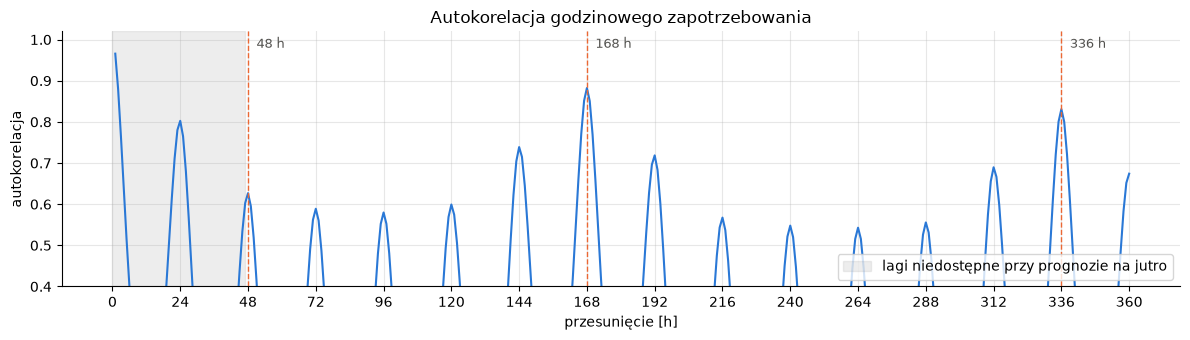

lag  24 h: 0.803
lag  48 h: 0.627
lag 168 h: 0.882
lag 336 h: 0.831


In [13]:
y = df["load_actual"]
lags = np.arange(1, 24 * 15 + 1)
acf = [y.autocorr(lag) for lag in lags]

fig, ax = plt.subplots(figsize=(12, 3.5))
ax.plot(lags, acf, color=BLUE)
ax.axvspan(0, 47, color=GREY, alpha=0.15, label="lagi niedostępne przy prognozie na jutro")
ax.legend(loc="lower right")
for lag in [48, 168, 336]:
    ax.axvline(lag, color=ORANGE, linestyle="--", linewidth=1)
    ax.text(lag + 3, 0.98, f"{lag} h", color="#52514e", fontsize=9)
ax.set_xticks(range(0, 24 * 15 + 1, 24))
ax.set_ylim(0.4, 1.02)
ax.set_xlabel("przesunięcie [h]")
ax.set_ylabel("autokorelacja")
ax.set_title("Autokorelacja godzinowego zapotrzebowania")
plt.tight_layout()
plt.show()

for lag in [24, 48, 168, 336]:
    print(f"lag {lag:>3} h: {y.autocorr(lag):.3f}")

**Wniosek:**
- Szczyty co 24 h to rytm doby, a najwyższe szczyty co 168 h (7 dni) to rytm tygodnia.
- **Lag 168 h (0,88) jest dużo lepszy niż lag 48 h (0,63).** Ta sama godzina tydzień temu to ten sam dzień
  tygodnia, a dwa dni temu to często zupełnie inny typ dnia (np. sobota dla poniedziałku).
- Lag 336 h (dwa tygodnie) to wciąż 0,83, więc można go rozważyć jako dodatkową cechę.

> **Co z tego wynika dla modelu:** zostawiamy lagi 48 h i 168 h. Ciekawy pomysł na nową cechę to
> **„ostatni dzień tego samego typu”**: dla poniedziałku ostatni dostępny dzień roboczy, a dla niedzieli
> poprzednia niedziela.

## 10. Gdzie myli się prognoza PSE?

To nasz benchmark. Szukamy godzin, miesięcy i typów dni, w których PSE myli się najbardziej, bo tam mamy
największą szansę ją pobić. **Bias = rzeczywiste − prognoza**, więc minus oznacza, że PSE **zawyża**.

PSE w całym okresie: MAE 410 MW, bias -123 MW, MAPE 2.3%


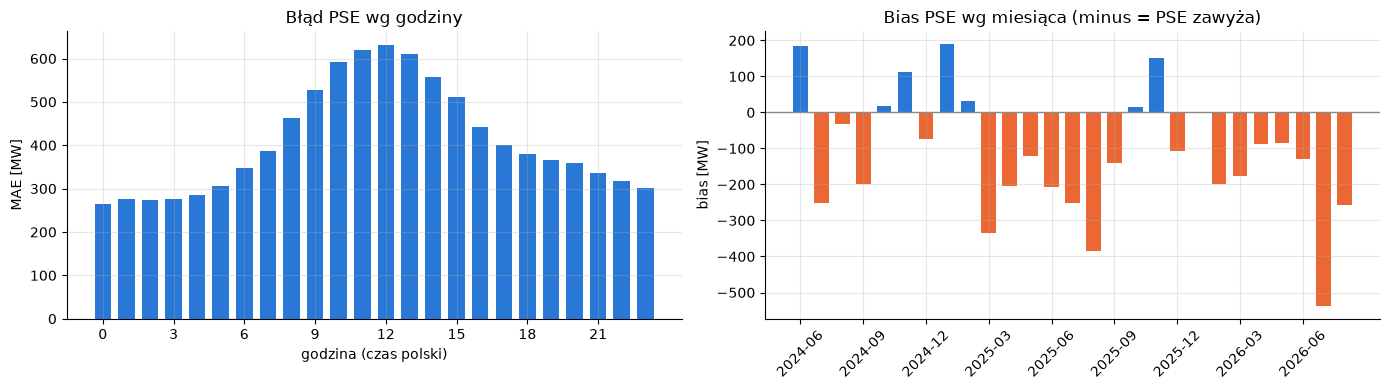


MAE PSE wg rodzaju dnia:
day_type
roboczy    403.0
weekend    415.0
święto     497.0


In [14]:
err = df["load_actual"] - df["load_fcst"]
print(
    f"PSE w całym okresie: MAE {err.abs().mean():.0f} MW, bias {err.mean():.0f} MW, "
    f"MAPE {(err.abs() / df['load_actual']).mean():.1%}"
)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4))
by_hour = err.abs().groupby(df["hour"]).mean()
ax1.bar(by_hour.index, by_hour.values, color=BLUE, width=0.7)
ax1.set_xticks(range(0, 24, 3))
ax1.set_xlabel("godzina (czas polski)")
ax1.set_ylabel("MAE [MW]")
ax1.set_title("Błąd PSE wg godziny")

by_month = err.groupby(df["date"].dt.to_period("M")).mean()
ax2.bar(
    by_month.index.astype(str),
    by_month.values,
    color=[BLUE if v >= 0 else ORANGE for v in by_month.values],
    width=0.7,
)
ax2.axhline(0, color=GREY, linewidth=1)
ax2.set_ylabel("bias [MW]")
ax2.set_title("Bias PSE wg miesiąca (minus = PSE zawyża)")
ax2.set_xticks(range(0, len(by_month), 3))
ax2.set_xticklabels(by_month.index.astype(str)[::3], rotation=45)
plt.tight_layout()
plt.show()

print("\nMAE PSE wg rodzaju dnia:")
print(err.abs().groupby(df["day_type"]).mean().round(0).to_string())

**Wniosek:**
- PSE myli się średnio o ok. **400 MW (ok. 2,3%)**, czyli bardzo dobrze. Pobicie tego wyniku nie będzie łatwe.
- **Błąd jest największy w środku dnia** (11:00–13:00, ok. 600+ MW), a ponad 2 razy mniejszy w nocy.
  Pokrywa się to z sekcją 8: w południe na zapotrzebowanie wpływa fotowoltaika, czyli zachmurzenie.
- **PSE systematycznie zawyża** (bias ok. −120 MW), najmocniej latem: w lipcu 2026 aż o ok. 500 MW.
- W święta PSE myli się wyraźnie bardziej (ok. 500 MW) niż w zwykłe dni (ok. 400 MW).

> **Co z tego wynika dla modelu:** realne szanse na pobicie PSE są w trzech miejscach:
> (1) lato i środek dnia, czyli lepsze wykorzystanie danych o słońcu,
> (2) korekta systematycznego zawyżania,
> (3) święta i dni mostowe.
> Uwaga uczciwościowa: PSE robi prognozę na podstawie *prognozy* pogody, a my w teście używamy *faktycznej*
> pogody. Porównanie jest więc na razie trochę nieuczciwe na naszą korzyść.

## 11. Podsumowanie: decyzje dla modelu

| # | Obserwacja | Decyzja |
|---|---|---|
| 1 | Dane kompletne, brak dziur, zmiana czasu poprawna | Bez imputacji, zostajemy przy UTC + kalendarzu w czasie polskim |
| 2 | Kształt doby zależy od rodzaju dnia **i** pory roku | Model musi łapać interakcje (drzewa to umieją, regresja liniowa wymaga ręcznych interakcji) |
| 3 | Pon. ok. −3%, sob. ok. −11%, niedz. ok. −19% względem wt–pt | Pełny `dayofweek`, a nie tylko `is_weekend` |
| 4 | Zapotrzebowanie rośnie **liniowo** z zimnem, ok. +240 MW/°C poniżej ok. 15 °C | Model zdolny do ekstrapolacji: regresja liniowa lub LightGBM z `linear_tree=True` |
| 5 | Zima 2025/26 dużo mroźniejsza niż 2024/25 | Foldy zimowe w CV będą trudne (ekstrapolacja). Raportować wynik CV osobno dla zimy |
| 6 | Brak wyraźnego trendu po usunięciu wpływu temperatury | Bez cechy trendu, poziom łapie `load_mean_7d` |
| 7 | Dni mostowe i okres świąteczny to −13 do −22% | Nowe cechy: `is_bridge_day`, `is_christmas_period` |
| 8 | Słońce obniża zapotrzebowanie w południe (PV za licznikiem) | `shortwave_radiation`/`cloud_cover` ważne; w produkcji potrzebna prognoza pogody |
| 9 | Lag 168 h dużo lepszy niż 48 h | Rozważyć lag 336 h i „ostatni dzień tego samego typu” |
| 10 | PSE: MAE ok. 400 MW, najgorzej w południe, latem i w święta; zawyża | Tu szukać przewagi; uczciwe porównanie wymaga prognozowanej pogody |

**Następny krok:** notebook 02 sprawdza te decyzje walidacją krzyżową, mierząc MAE każdego wariantu.